### Setup

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## turn off scientific notation
pd.set_option('display.float_format', '{:.6f}'.format) 
## display max columns/rows
pd.set_option('display.max_columns', 100)
pd.set_option("display.max_rows", 200)

## load energy dataset
owid = pd.read_csv("data/workingdata/owid-energy-data.csv")

# **Kathy**: What progress are the world's largest economies (the United States, China, and Germany) making towards Paris Climate Accords goals? 
Shola’s plots show an increasing demand for energy over time, so it is critical that countries also address the question of CO2 emissions if we are to meet the challenge of climate change. In the next few plots, I will use Our World in Data’s indicators on energy and CO2 emissions to ask whether the world’s three largest economies – the United States, China, and Germany – are making progress toward the goals of the Paris Climate Agreement, specifically looking at decreased CO2 emissions.

### (1) Load CO2 dataset (2) Filter out rows before 2000 and country aggregates (3) Merge OWID CO2 dataset with OWID energy dataset

In [70]:
## load energy dataset
owid = pd.read_csv("data/workingdata/owid-energy-data.csv")
## load CO2 dataset 
co2_full = pd.read_csv("data/suppdata/owid-co2-data.csv")

#select only necessary columns in co2 dataset
co2_cols = ['country', 'year', 'iso_code', 'population', 'gdp', 'co2', 'co2_per_capita', 'co2_per_gdp', 
            'co2_per_unit_energy', 'co2_including_luc_per_unit_energy', 'consumption_co2', 
            'consumption_co2_per_gdp', 'consumption_co2_per_capita']
print("++Before selecting columns in CO2 data:", co2_full.shape) # (50191, 79)
co2_full = co2_full[co2_cols]
print("++After selecting columns in CO2 data:", co2_full.shape) # (50191, 13)

#select only necessary columns in energy dataset 
energy_cols = ['country', 'year', 'iso_code', 'energy_per_capita', 'energy_per_gdp', 
              'primary_energy_consumption', 'renewables_share_energy', 'nuclear_share_energy', 
              'fossil_share_energy', 'low_carbon_share_energy', 'low_carbon_consumption']
print("**Before selecting columns in energy data:", owid.shape) # (23195, 130)
owid_c = owid[energy_cols]
print("**After selecting columns in energy data:", owid_c.shape) # (23195, 11)

## filter out pre-2000 rows in both datasets
print("--Before filter years in CO2 data:", co2_full.shape) # (50191, 13)
co2_full = co2_full[co2_full['year'] >= 2000]
print("--After filter years in CO2 data:", co2_full.shape) # (6120, 13)

print("^^Before filter years in energy data:", owid_c.shape) # (23195, 11)
owid_c = owid_c[owid_c['year'] >= 2000]
print("^^After filter years in energy data:", owid_c.shape) # (7454, 11)

#filter out country aggregates
iso_mask = owid_c['iso_code'].str.len().eq(3)
print("&&Before filter iso codes in energy data:", owid_c.shape) # (7454, 11)
owid_c = owid_c[iso_mask].copy()
#owid_c = owid_c[~owid_c['iso_code'].isin(drop_iso)].copy()
print("&&After filter iso codes in energy data:", owid_c.shape) # (5383, 11)

iso_mask = co2_full['iso_code'].str.len().eq(3)
print("==Before filter iso codes in co2 data:", co2_full.shape) # (6120, 13)
co2_full = co2_full[iso_mask].copy()
print("==After filter iso codes in co2 data:", co2_full.shape) # (5232, 13)

## merge CO2 and energy datasets
print("->Before merge co2:", owid_c.shape, "AND", co2_full.shape) #owid (5383, 11), co2 (5232, 13)
owidco2_df = owid_c.merge(co2_full, on=['country', 'year'], how="left", validate="one_to_one", indicator="_merge_co2")
print("->After merge co2:", owidco2_df.shape) # (5383, 23)

++Before selecting columns in CO2 data: (50191, 79)
++After selecting columns in CO2 data: (50191, 13)
**Before selecting columns in energy data: (23195, 130)
**After selecting columns in energy data: (23195, 11)
--Before filter years in CO2 data: (50191, 13)
--After filter years in CO2 data: (6120, 13)
^^Before filter years in energy data: (23195, 11)
^^After filter years in energy data: (7454, 11)
&&Before filter iso codes in energy data: (7454, 11)
&&After filter iso codes in energy data: (5383, 11)
==Before filter iso codes in co2 data: (6120, 13)
==After filter iso codes in co2 data: (5232, 13)
->Before merge co2: (5383, 11) AND (5232, 13)
->After merge co2: (5383, 23)


### Filter out NaNs in target columns and filter to target countries

In [71]:
#filter out NaNs in key columns
key_cols = ['country', 'year', 'population', 'gdp', 'co2', 'consumption_co2', 'primary_energy_consumption']
print("++Before filter out NaNs:", owidco2_df.shape) # (5383, 23)
owidco2_df = owidco2_df.dropna(subset=key_cols)
print("++After filter out NaNs:", owidco2_df.shape) # (2727, 23)
owidco2_df.head()

# subset target countries to create owidco2 dataframe
target_countries = ["United States", "China", "Germany"]
country_bool = owidco2_df['country'].isin(target_countries)

print("**Before filter out countries:", owidco2_df.shape) # (2727, 23)
owidco2c = owidco2_df[country_bool].copy()
print("**After filter out countries:", owidco2c.shape) # (69, 23)

# create table with global values to create owidco2g dataframe
cols_for_table = ['co2', 'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'co2_including_luc_per_unit_energy', 
               'consumption_co2', 'consumption_co2_per_gdp', 'consumption_co2_per_capita', 'energy_per_capita', 
               'energy_per_gdp', 'fossil_share_energy', 'low_carbon_share_energy', 'nuclear_share_energy', 
               'primary_energy_consumption', 'renewables_share_energy', 'population', 'gdp', 'low_carbon_consumption']
print("==Before form global:", owidco2_df.shape) # (2727, 23)
owidco2g = (
    owidco2_df.groupby('year', as_index=False)[cols_for_table]
    .agg({
        'population': 'sum', 
        'gdp':'sum', 
        'co2':'sum', 
        'consumption_co2':'sum', 
        'primary_energy_consumption':'sum',
        'low_carbon_consumption': 'sum'})
          )
print("==After form global:", owidco2g.shape) # (23, 7)
owidco2g['co2_per_capita'] = ((owidco2g['co2'] *1e6) / owidco2g['population'])
owidco2g['gdp_per_capita'] = owidco2g['gdp'] / owidco2g['population']
owidco2g['consumption_co2_per_capita'] = ((owidco2g['consumption_co2'] * 1e6) / owidco2g['population'])
owidco2g['co2_per_gdp'] = ((owidco2g['co2'] *1e6) / owidco2g['gdp'])
owidco2g['consumption_co2_per_gdp'] = ((owidco2g['consumption_co2'] * 1e6)/owidco2g['gdp'])
owidco2g['energy_per_capita'] = ((owidco2g['primary_energy_consumption'] *1e9) / owidco2g['population'])
owidco2g['energy_per_gdp_calc'] = (owidco2g['primary_energy_consumption'] * 1e9 / owidco2g['gdp'])
owidco2g['low_carbon_share_energy'] = (owidco2g['low_carbon_consumption'] / owidco2g['primary_energy_consumption'] * 100)
owidco2g['co2_per_unit_energy'] = owidco2g['co2'] / owidco2g['primary_energy_consumption']
print("==After add columns to global:", owidco2g.shape) # (23, 16)


++Before filter out NaNs: (5383, 23)
++After filter out NaNs: (2727, 23)
**Before filter out countries: (2727, 23)
**After filter out countries: (69, 23)
==Before form global: (2727, 23)
==After form global: (23, 7)
==After add columns to global: (23, 16)


## **Plot 1**: What are CO2 emissions levels 2000-2015?
This first plot shows the trend for these three countries in CO2 emissions (shown in tons per person) from 2000 to 2015 when the Paris agreement was signed. As you can see the US and Germany were making some progress in decreasing emissions while China had a slight increase. Globally, the world saw a small increase in emissions per person over this period. At the global level, there is a modest increase. Countries have two paths to reduce emissions: (1) using energy more efficiently and (2) switching from fossil fuels to low-carbon sources like nuclear, wind or solar. My next two charts will look at the degree to which these three countries are making progress on these fronts. 

In [72]:
### clean and shape data for Plot 1

## shape dataframe for US, Germany, and China

# drop NAs in key columns and create q1 dataframe (owidco2_q1)
owidco2_q1 = owidco2c[['country', 'year', 'co2', 'co2_per_capita']].dropna(subset=['co2', 'co2_per_capita'])
# filter out anything after 2015 (so data is 2000-2015)
print("++Before filter years in CO2 country data:", owidco2c.shape) # (69, 23)
owidco2_q1 = owidco2_q1[owidco2_q1['year'] <= 2015]
print("++After filter years in CO2 country data:", owidco2_q1.shape) # (48, 4)

## shape dataframe for global data (owidco2g_q1)
# drop NAs in key columns
owidco2g_q1 = owidco2g[['year', 'co2', 'co2_per_capita']].dropna(subset=['co2', 'co2_per_capita'])
# filter out anything after 2015 (so data is 2000-2015)
print("==Before filter years in CO2 global data:", owidco2g.shape) # (23, 16)
owidco2g_q1 = owidco2g_q1[owidco2g_q1['year'] <= 2015]
print("==After filter years in CO2 global data:", owidco2g_q1.shape) # (16, 3)


++Before filter years in CO2 country data: (69, 23)
++After filter years in CO2 country data: (48, 4)
==Before filter years in CO2 global data: (23, 16)
==After filter years in CO2 global data: (16, 3)


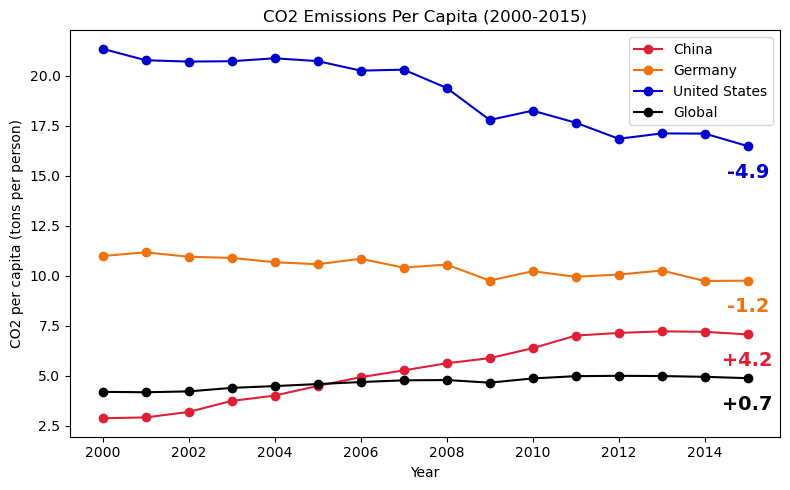

In [73]:
### code for Plot 1

## colors for countries (and global)
colors= {
    'China': '#e01f37',
    "United States": 'mediumblue',
    'Germany': '#f0720f',
    'Global': 'black'
}

## plot 1
fig, ax = plt.subplots(figsize=(8,5))

## plotting data for US, Germany and China
for country, df1 in owidco2_q1.groupby('country'):
    ax.plot(df1['year'], df1['co2_per_capita'],
            marker = 'o', label = country, color = colors[country])
    
    # calculating and annotating change for US, Germany, and China
    q1_2000 = df1.loc[df1['year'] == 2000, 'co2_per_capita'].iloc[0]
    q1_2015 = df1.loc[df1['year'] == 2015, 'co2_per_capita'].iloc[0]
    diff1 = q1_2015 - q1_2000
    txt1 = f"{diff1:+.1f}"

    ax.annotate(txt1, 
                xy = (2015,q1_2015),
                xytext = (0,-12),
                textcoords="offset points",
                ha = "center",
                va = "top",
                color=colors[country],
                fontsize=14,
                fontweight="bold"
                )

## plotting global data
ax.plot(owidco2g_q1['year'],
        owidco2g_q1['co2_per_capita'],
        marker='o',
        label="Global",
        color=colors["Global"])

## calculating and annotating change for global data
q1_2000g = owidco2g_q1.loc[owidco2g_q1['year'] == 2000, 'co2_per_capita'].iloc[0]
q1_2015g = owidco2g_q1.loc[owidco2g_q1['year'] == 2015, 'co2_per_capita'].iloc[0]
diff1_g = q1_2015g - q1_2000g
txt1_g =f"{diff1_g:+.1f}"

ax.annotate(
    txt1_g,
    xy = (2015, q1_2015g),
    xytext = (0,-12),
    textcoords="offset points",
    ha = 'center',
    va = "top",
    color = colors["Global"],
    fontsize = 14,
    fontweight = "bold"
)

## setting chart labels and legend
ax.set_xlabel("Year")
ax.set_ylabel("CO2 per capita (tons per person)")
ax.set_title("CO2 Emissions Per Capita (2000-2015)")
ax.legend()

plt.tight_layout()
plt.show()


## **Plot 2**: Has there been a change in energy efficiency?
This chart plots `energy_per_gdp`, which is a measure of how much energy is required to produce a unit of economic output (measured in kilowatt-hours per international dollar). A lower value means the economy is becoming more energy efficient and implies they are producing more goods and services for each unit of energy consumed. This chart shows clear decreases over time for Germany, the US, and China, culminating in a global improvement. These trends can come from better technology, stricter efficiency standards for buildings and vehicles, and structural changes in the economy toward services and higher-value manufacturing.  This is also a good sign for meeting Paris climate goals and shows some decoupling between economic growth and energy consumption.


In [74]:
### clean and shape data for Plot 2

# drop NAs in key columns for country data (no NAs)
cols_to_keep2 = ['energy_per_gdp']
print("++Before filter out NaNs in country data:", owidco2c.shape) # (69, 23)
owidco2_q2 = owidco2c.dropna(subset=cols_to_keep2)
print("++After filter out NaNs in country data:", owidco2_q2.shape) # (69, 23)

# drop NAs in key columns for global data and sort by year (no NAs)
cols_to_keep2g = ['energy_per_gdp_calc']
print("==Before filter out NaNs in global data:", owidco2g.shape) # (23, 16)
owidco2g_q2 = owidco2g.dropna(subset=cols_to_keep2g)
print("==After filter out NaNs in global data:", owidco2g_q2.shape) # (23, 16)
owidco2g_q2 = owidco2g.sort_values('year')

++Before filter out NaNs in country data: (69, 23)
++After filter out NaNs in country data: (69, 23)
==Before filter out NaNs in global data: (23, 16)
==After filter out NaNs in global data: (23, 16)


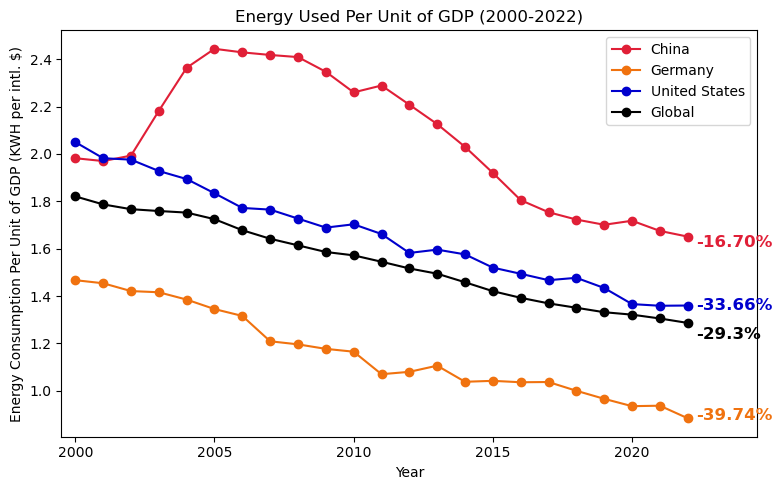

In [75]:
### code for Plot 2

## colors for countries (and global)
colors= {
    'China': '#e01f37',
    "United States": 'mediumblue',
    'Germany': '#f0720f',
    'Global': 'black'
}

# offset for numbers on right side
y_offset2 = {
    "China": -4,
    "United States": 0,
    "Germany": 2,
    "Global": -8
}

# start and end years for chart
start2 = 2000
end2 = 2022

## plot 2
fig, ax = plt.subplots(figsize=(8,5))

# plot country data
for country, df2 in owidco2_q2.groupby('country'):
    df2 = df2.sort_values('year')
    
    ax.plot(
        df2['year'], 
        df2['energy_per_gdp'],
        marker = 'o',
        label = country,
        color = colors[country]
    )

    # calculating and annotating change for country data
    year2beg = df2.loc[df2['year'] == start2, 'energy_per_gdp'].iloc[0]
    year2end = df2.loc[df2['year'] == end2, 'energy_per_gdp'].iloc[0]
    pct2 = (year2end - year2beg) / year2beg * 100
    txt2 = f"{pct2:+.2f}%"

    ax.annotate(
        txt2,
        xy = (end2, year2end),
        xytext = (6, y_offset2[country]),
        textcoords = "offset points",
        ha = 'left',
        va = 'center',
        color = colors[country],
        fontsize = 12,
        fontweight = "bold"
)

# plot global data
ax.plot(
    owidco2g_q2['year'],
    owidco2g_q2['energy_per_gdp_calc'],
    marker = 'o',
    label = "Global",
    color = colors["Global"]
)

# calculating and annotating change for country data
year2gbeg = owidco2g_q2.loc[owidco2g_q2['year'] == start2, 'energy_per_gdp_calc'].iloc[0] 
year2gend = owidco2g_q2.loc[owidco2g_q2['year'] == end2, 'energy_per_gdp_calc'].iloc[0] 
pct2g = (year2gend - year2gbeg) / year2gbeg * 100
txt2g = f"{pct2g:+.1f}%"

ax.annotate(
    txt2g,
    xy = (end2, year2gend),
    xytext = (6, y_offset2["Global"]),
    textcoords = "offset points",
    ha = "left",
    va = "center",
    color = colors["Global"],
    fontsize = 12,
    fontweight = "bold"
)

## setting chart labels and legend
ax.set_xlim(start2 - 0.5, end2 + 2.5)
ax.set_title("Energy Used Per Unit of GDP (2000-2022)")
ax.set_xlabel("Year")
ax.set_ylabel("Energy Consumption Per Unit of GDP (KWH per intl. $)")

plt.legend()
plt.tight_layout()
plt.show()


## **Plot 3**: Is there a change in the use of low-carbon energy sources?
This chart shows the change in use of low-carbon energy sources between 2000 and 2022. As you can see there are clear upward trends with the US, China, and Germany increasing their use by 4-12% in the share of low-carbon energy in their total mix. That means coal, oil, and gas are gradually being displaced by renewables and nuclear.  At the global level, we again see a steady but not dramatic rise, raising the question of whether this transition is fast enough to counter both population growth and rising energy use per person.

In [76]:
### clean and shape data for Plot 3

# specify target years
years3 = [2000, 2022]

## shaping country dataframe
# filter to target columns
cols_to_keep3 = ['country', 'year', 'low_carbon_share_energy']
print("++Before filter out excess columns:", owidco2c.shape) # (69, 23)
owidco2_q3 = owidco2c[cols_to_keep3]
print("++After filter out excess columns:", owidco2_q3.shape) # (69, 3)
# drop NAs in target column
print("==Before filter out NaNs:", owidco2_q3.shape) # (69, 3)
owidco2_q3 = owidco2_q3.dropna(subset=['low_carbon_share_energy'])
print("==After filter out NaNs:", owidco2_q3.shape) # (69, 3)
# filter out all years but 2000 and 2022
owidco2_q3 = owidco2_q3[owidco2_q3['year'].isin(years3)]
# create pivot table
owidco2_q3p = owidco2_q3.pivot(index = "country", columns = "year", values = "low_carbon_share_energy")

## shaping global dataframe
# filter to target columns
print("**Before filter out columns and NaNs in global data:", owidco2g.shape) # (23, 2)
owidco2g_q3 = owidco2g[['year', 'low_carbon_share_energy']]
# drop NAs in key columns 
owidco2g_q3 = owidco2g_q3.dropna(subset=['low_carbon_share_energy'])
print("**After filter out columns and NaNs in global data:", owidco2g_q3.shape) # (23, 2)
# keep only target years (2000, 2022)
owidco2g_q3 = (
    owidco2g_q3[owidco2g_q3['year'].isin(years3)].set_index('year')[['low_carbon_share_energy']].T
)
owidco2g_q3.index = ["Global"]

# concatenate to create a single Plot 3 dataframe
owidco2_q3p = pd.concat([owidco2_q3p, owidco2g_q3])


++Before filter out excess columns: (69, 23)
++After filter out excess columns: (69, 3)
==Before filter out NaNs: (69, 3)
==After filter out NaNs: (69, 3)
**Before filter out columns and NaNs in global data: (23, 16)
**After filter out columns and NaNs in global data: (23, 2)


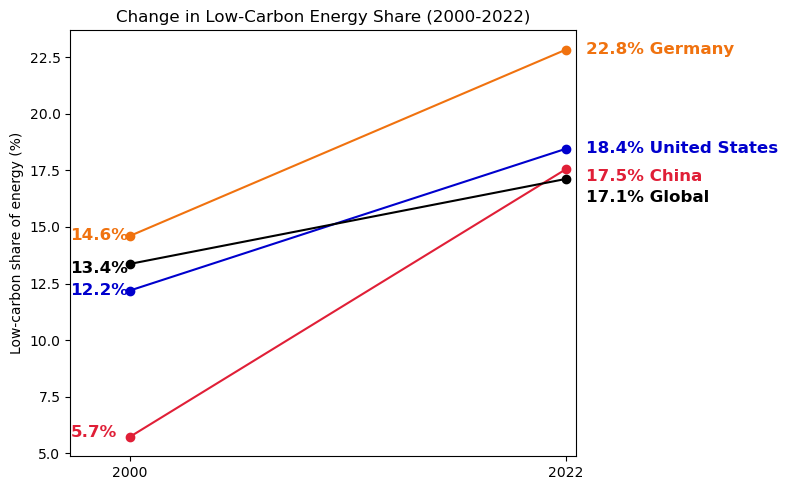

In [77]:
# Code for Plot 3

# colors for countries (and global)
colors= {
    'China': '#e01f37',
    "United States": 'mediumblue',
    'Germany': '#f0720f',
    'Global': 'black'
}

# offset for numbers on left side
left_y_offset = {
    "China": 0.2,
    "Germany": 0.0,
    "United States": 0.0,
    "Global": -0.2
}

# offset for numbers on right side
right_y_offset = {
    "China": -0.3,
    "Germany": 0.0,
    "United States": 0.0,
    "Global": -0.8
}

# Plot 3
fig, ax = plt.subplots(figsize=(8,5))

# plot data, calculate change, and annotate plot                       
for name, row in owidco2_q3p.iterrows():
    txt3a = row[years3[0]]
    txt3b = row[years3[1]]
    ax.plot(years3, [txt3a, txt3b],
            marker = 'o',
            color = colors[name])
    ax.text(years3[0] - 3,
            txt3a + left_y_offset[name],
            f'{txt3a:.1f}%',
            ha = "left", 
            va = "center", 
            color = colors[name], 
            fontsize = 12, 
            fontweight = "bold")
    ax.text(years3[1] + 1,
            txt3b + right_y_offset[name],
            f'{txt3b:.1f}% {name}',
            ha = "left", 
            va = "center", 
            color = colors[name], 
            fontsize = 12, 
            fontweight = "bold"
    )

## setting chart labels and legend
ax.set_xlim(years3[0] - 3, years3[1] + 0.5)
ax.set_xticks(years3)
ax.set_ylabel("Low-carbon share of energy (%)")
ax.set_title("Change in Low-Carbon Energy Share (2000-2022)")

plt.tight_layout()
plt.show()


## **Plot 4**: Are current CO2 emissions lower?
Overall, global CO2 emissions seem to be holding steady or dropping slightly, which is better than increasing. Though China’s achievements in energy efficiency and renewable expansion are not holding down their CO2 emissions, the US and Germany have achieved significant decreases in per capita emissions, at least in 2023. The key question is whether these trends can accelerate and spread, so that global emissions fall fast enough to align with the Paris trajectory.  The data suggest that the tools—efficiency and low-carbon energy—are working; the challenge is scaling them up quickly and consistently across all major economies.

In [78]:
### clean and shape data for Plot 4

# target years and countries
years4 = [2015, 2023]
countries4 = ["United States", "China", "Germany"]

## shape country dataframe
# create mask to filter out country aggregates
iso_mask2 = co2_full['iso_code'].str.len().eq(3)
# filter out NAs and country aggregates and to target colums and rows
print("Before filter to target columns/rows and drop NAs:", co2_full.shape) # (5232, 13)
co2_full4 = co2_full[iso_mask2].copy()
owidco2_q4 = co2_full4[['country', 'year', 'co2_per_capita']].dropna(subset=['co2_per_capita'])
owidco2_q4 = owidco2_q4[(owidco2_q4['country'].isin(countries4)) & (owidco2_q4['year'].isin(years4))]
print("After filter to target columns/rows and drop NAs:", owidco2_q4.shape) # (6, 3)

## shape global dataframe
# create the dataframe from the filtered original co2 dataset
owidco2g_q4 = (
    co2_full4.groupby('year', as_index=False)[['country', 'co2', 'population']]
    .agg({
        'population': 'sum', 
        'co2':'sum'})
          )
owidco2g_q4['co2_per_capita'] = ((owidco2g_q4['co2'] *1e6) / owidco2g_q4['population'])
# filter to target columns
owidco2g_q4 = owidco2g_q4[['year', 'co2_per_capita']]
# filter to target years
owidco2g_q4 = owidco2g_q4[owidco2g_q4['year'].isin(years4)].copy()
# add "Global" to country column for label
owidco2g_q4['country'] = 'Global'

# combine into one dataframe
q4 = pd.concat([owidco2_q4, owidco2g_q4], ignore_index=True)


Before filter to target columns/rows and drop NAs: (5232, 13)
After filter to target columns/rows and drop NAs: (6, 3)


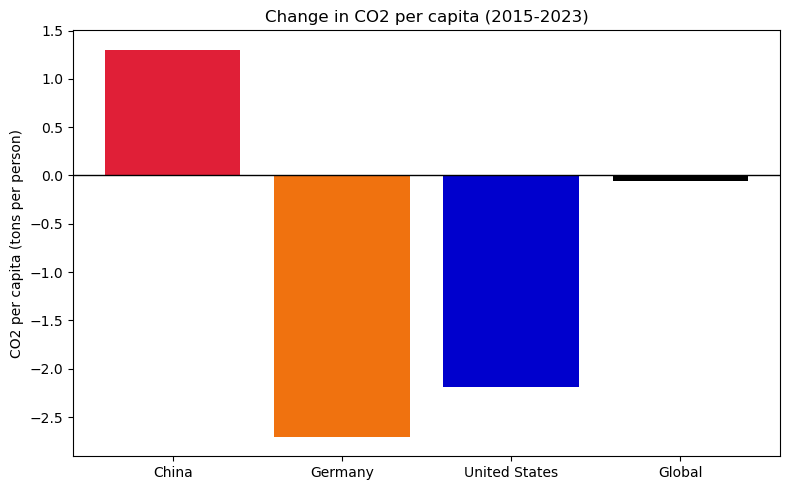

In [79]:
# Code for Plot 4

# colors for countries/global
colors= {
    'China': '#e01f37',
    "United States": 'mediumblue',
    'Germany': '#f0720f',
    'Global': 'black'
}

# pivot table for three countries
owidco2_q4p = q4.pivot(
    index = "country",
    columns = "year",
    values = "co2_per_capita"
)

# creating the values for the bar chart for the three countries + global
diff4 = owidco2_q4p[2023] - owidco2_q4p[2015]
order4 = ["China", "Germany", "United States", "Global"]
diff4 = diff4.loc[order4]
#diff4g = owidco2g_q4.loc[2023] - owidco2g_q4[2015]
colorlst = [colors[c] for c in diff4.index]

# combine 3 countries and global
#q4_df = diff4.copy()
#q4_df.loc["Global"] = diff4g
#q4_df = q4_df.reindex(["China", "Germany", "United States", "Global"])

# plot
fix, ax = plt.subplots(figsize=(8,5))
ax.bar(diff4.index, diff4.values, color = colorlst)
ax.axhline(0, linewidth = 1, color = "black")

## setting chart labels and legend
ax.set_ylabel("CO2 per capita (tons per person)")
ax.set_title("Change in CO2 per capita (2015-2023)")

plt.tight_layout()
plt.show()

##